                            OLS Regression Results                            
Dep. Variable:                  voted   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.080
Method:                 Least Squares   F-statistic:                     2492.
Date:                Tue, 29 Sep 2026   Prob (F-statistic):               0.00
Time:                        15:20:42   Log-Likelihood:            -2.1033e+05
No. Observations:              344084   AIC:                         4.207e+05
Df Residuals:                  344071   BIC:                         4.208e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
treatment_1     0.0249      0.002      9.981      

C:\Users\jonat\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: UserWarning: Coordinate descent without L1 regularization may lead to unexpected results and is discouraged. Set l1_ratio > 0 to add L1 regularization.
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\jonat\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.435e+04, tolerance: 1.087e+01
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\jonat\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: UserWarning: Coordinate descent without L1 regularization may lead to unexpected results and is discouraged. Set l1_ratio > 0 to add L1 regularization.
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\jonat\anaconda3\Lib\site-packages\sklearn\linear_m

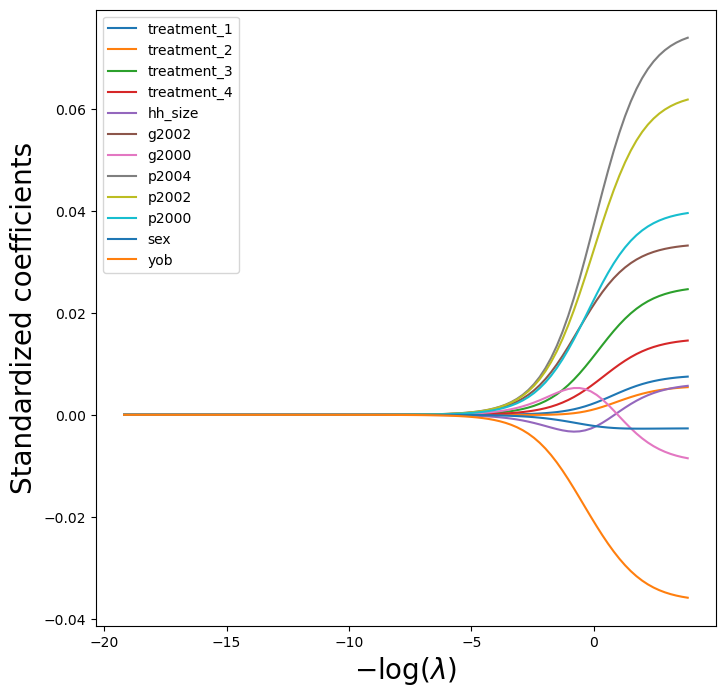

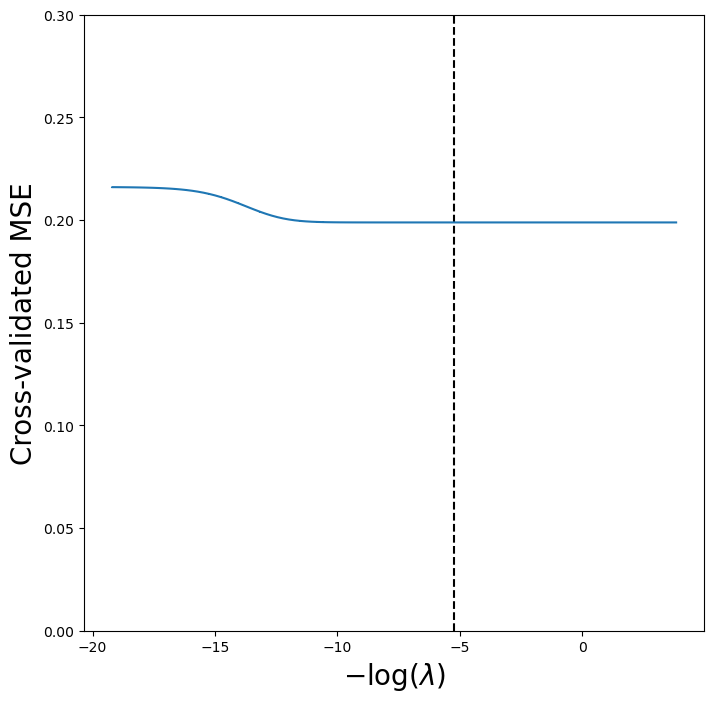

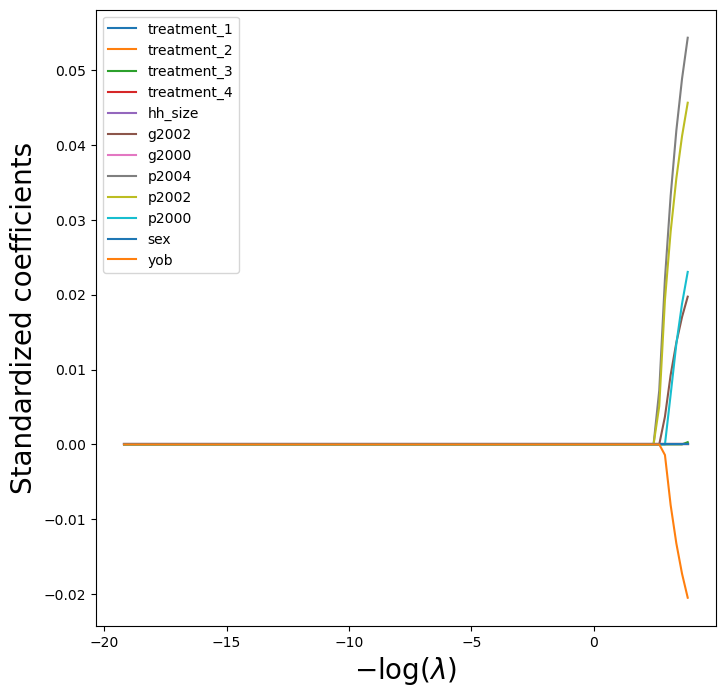

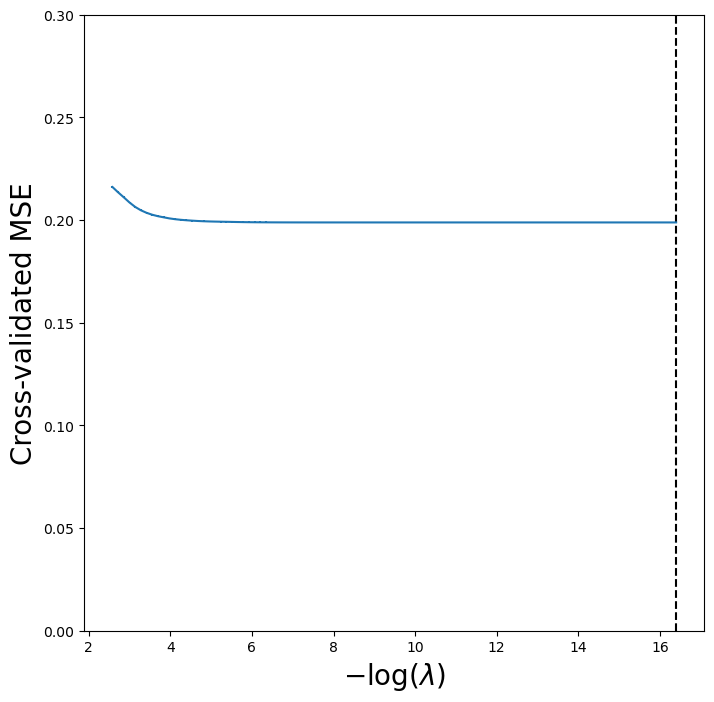

In [14]:
# Importing data analysis package:

import pandas as pd
import numpy as np
import statsmodels.api as sm
from statsmodels.api import OLS
from ISLP.models import ModelSpec as MS
import sklearn.linear_model as skl
from matplotlib.pyplot import subplots
from ISLP.models import \
     (Stepwise,
      sklearn_selected,
      sklearn_selection_path)
import sklearn.model_selection as skm
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

# Importing dataset:

dataset = pd.read_stata(
    r"C:\Users\jonat\OneDrive\Desktop\Uni\Gerber et al 2008\GerberGreenLarimer_APSR_2008_social_pressure.dta",
    convert_categoricals=False
)

# Define treatment dummy variables and add them back into dataset:

dataset["treatment"] = dataset["treatment"].astype(int)
treatment_dummies = pd.get_dummies(dataset['treatment'], prefix='treatment', dtype=int)
dataset = pd.concat([dataset, treatment_dummies], axis=1)

# Define variables for analysis:

variables = [
    "voted",
    "treatment_1",
    "treatment_2",
    "treatment_3",
    "treatment_4",
    "hh_size",
    "g2004",
    "g2002",
    "g2000",
    "p2004",
    "p2002",
    "p2000",
    "sex",
    "yob"
]

# Setting up OLS model:

Y = dataset["voted"]
X = dataset[variables[1:]]
X = sm.add_constant(X)

# Running OLS Model:

OLS_Model = sm.OLS(Y,X).fit()
print(OLS_Model.summary())

# Generate the LaTeX output for the regression table
print(OLS_Model.summary().as_latex())

# Ridge Regression:

# Creating predictor list, dropping g2004 due to having zero variance:

predictors = [
    "treatment_1",
    "treatment_2",
    "treatment_3",
    "treatment_4",
    "hh_size",
    "g2002",
    "g2000",
    "p2004",
    "p2002",
    "p2000",
    "sex",
    "yob"
]

#Making two graphs:

design = MS(predictors).fit(dataset)

D = design.fit_transform(dataset)
D = D.drop('intercept', axis=1)
X = np.asarray(D)

Xs = X - X.mean(0)[None,:]
X_scale = X.std(0)
Xs = Xs/ X_scale[None,:]
lambdas = 10**np.linspace(8, -2, 100) / Y.std()
soln_array = skl.ElasticNet.path(Xs,
                                 Y,
                                 l1_ratio=0.,
                                 alphas=lambdas)[1]

soln_path = pd.DataFrame(soln_array.T,
                         columns=D.columns,
                         index=-np.log(lambdas))
soln_path.index.name = 'negative log(lambda)'


path_fig, ax = subplots(figsize=(8,8))
soln_path.plot(ax=ax, legend=False)
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20)
ax.legend(loc='upper left');  

ridgeCV = skl.RidgeCV(alphas=lambdas, store_cv_results=True)

pipeCV = Pipeline([
    ('ridge', ridgeCV)
])

pipeCV.fit(Xs, Y)

tuned_ridge = pipeCV.named_steps['ridge']
ridgeCV_fig, ax = subplots(figsize=(8,8))
ax.errorbar(
    -np.log(lambdas),
    tuned_ridge.cv_results_.mean(0),
    yerr=tuned_ridge.cv_results_.std(0) / np.sqrt(len(Y))
)
ax.axvline(-np.log(tuned_ridge.alpha_), c='k', ls='--')
ax.set_ylim([0,0.3])
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20);

# LASSO Regression:

D = design.fit_transform(dataset)
D = D.drop('intercept', axis=1)
X = np.asarray(D)

lasso_soln_array = skl.ElasticNet.path(
    Xs,
    Y,
    l1_ratio=1.,
    alphas=lambdas
)[1]

soln_path = pd.DataFrame(lasso_soln_array.T,
                         columns=D.columns,
                         index=-np.log(lambdas))
soln_path.index.name = 'negative log(lambda)'
soln_path

path_fig, ax = subplots(figsize=(8,8))
soln_path.plot(ax=ax, legend=False)
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Standardized coefficients', fontsize=20)
ax.legend(loc='upper left');

K = 5
kfold = skm.KFold(K,
                  random_state=0,
                  shuffle=True)

scaler = StandardScaler(with_mean=True,  with_std=True)

lassoCV = skl.ElasticNetCV(n_alphas=100,
                           eps=1e-6,
                           l1_ratio=1,
                           cv=kfold)
pipeCV = Pipeline(steps=[('scaler', scaler),
                         ('lasso', lassoCV)])
pipeCV.fit(X, Y)
tuned_lasso = pipeCV.named_steps['lasso']
tuned_lasso.alpha_

lassoCV_fig, ax = subplots(figsize=(8,8))
ax.errorbar(-np.log(tuned_lasso.alphas_),
            tuned_lasso.mse_path_.mean(1),
            yerr=tuned_lasso.mse_path_.std(1) / np.sqrt(K))
ax.axvline(-np.log(tuned_lasso.alpha_), c='k', ls='--')
ax.set_ylim([0,0.3])
ax.set_xlabel(r'$-\log(\lambda)$', fontsize=20)
ax.set_ylabel('Cross-validated MSE', fontsize=20);

                            OLS Regression Results                            
Dep. Variable:                  voted   R-squared:                       0.080
Model:                            OLS   Adj. R-squared:                  0.080
Method:                 Least Squares   F-statistic:                     2492.
Date:                Tue, 29 Sep 2026   Prob (F-statistic):               0.00
Time:                        15:19:18   Log-Likelihood:            -2.1033e+05
No. Observations:              344084   AIC:                         4.207e+05
Df Residuals:                  344071   BIC:                         4.208e+05
Df Model:                          12                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
treatment_1     0.0249      0.002      9.981      

C:\Users\jonat\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: UserWarning: Coordinate descent without L1 regularization may lead to unexpected results and is discouraged. Set l1_ratio > 0 to add L1 regularization.
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\jonat\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: ConvergenceWarning: Objective did not converge. You might want to increase the number of iterations, check the scale of the features or consider increasing regularisation. Duality gap: 5.435e+04, tolerance: 1.087e+01
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\jonat\anaconda3\Lib\site-packages\sklearn\linear_model\_coordinate_descent.py:681: UserWarning: Coordinate descent without L1 regularization may lead to unexpected results and is discouraged. Set l1_ratio > 0 to add L1 regularization.
  model = cd_fast.enet_coordinate_descent_gram(
C:\Users\jonat\anaconda3\Lib\site-packages\sklearn\linear_m

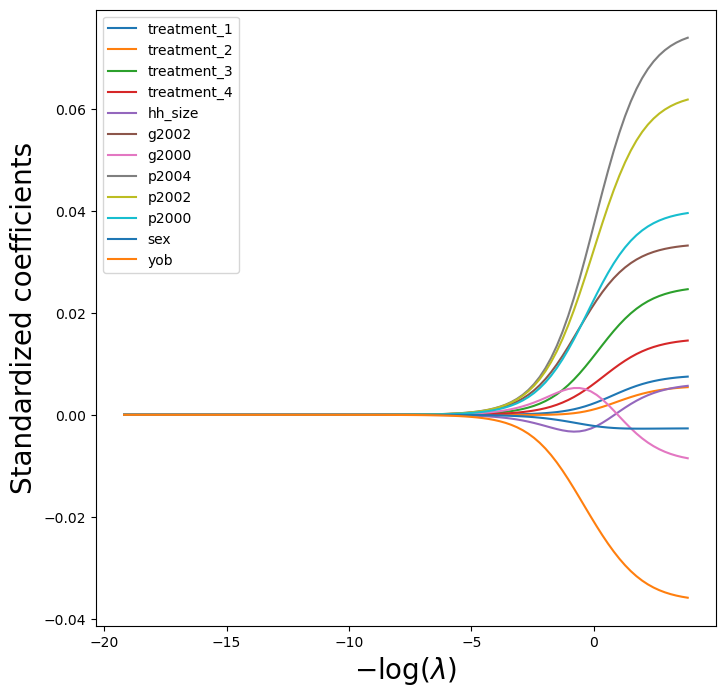

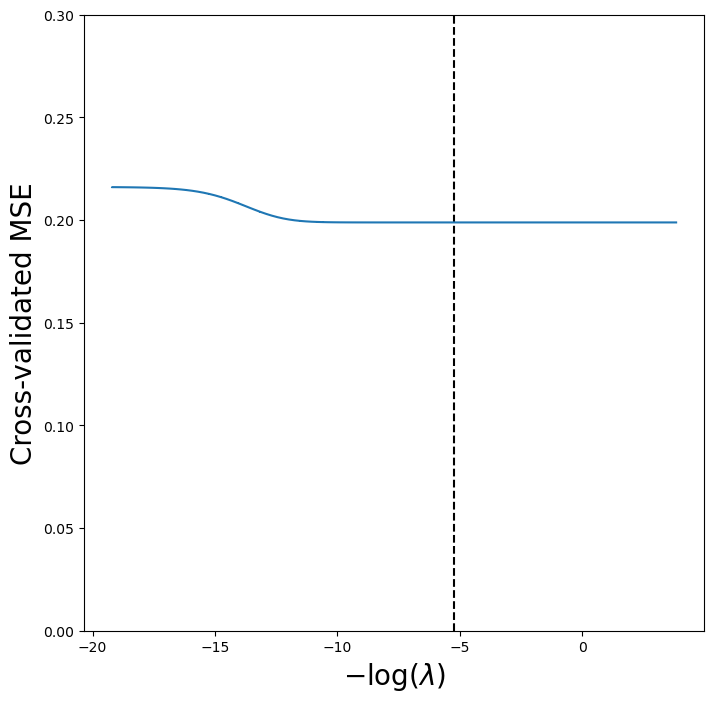

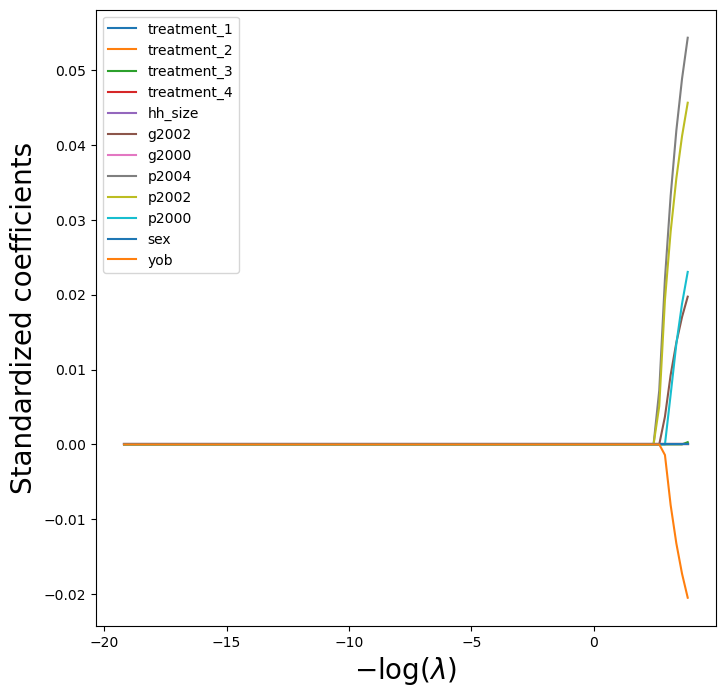

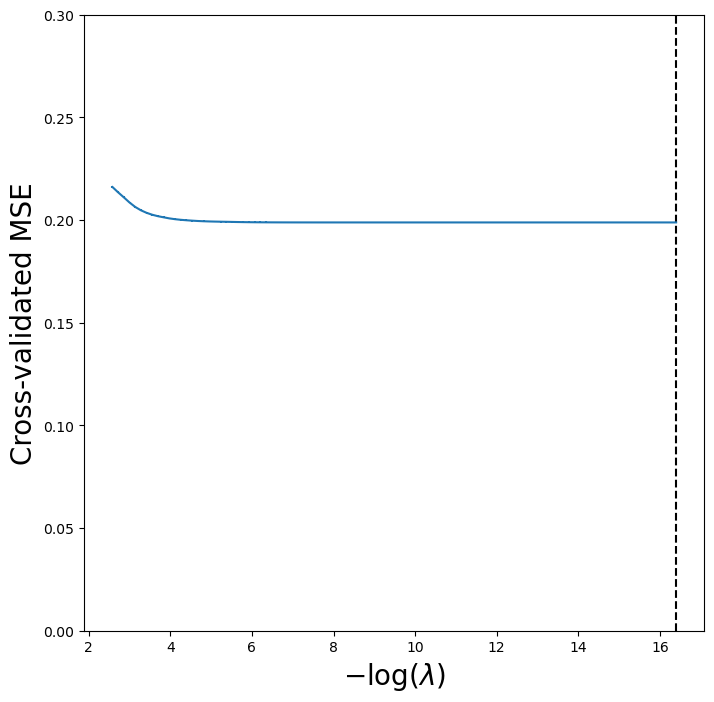